In [1]:
from typing import TypedDict
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph,START,END
from loguru import logger


#1. 构建子图
#1.1 声明子图的状态
class SubgraphState(TypedDict):
    raw_text:str #未清洗的文本
    stripped_text:str # 去除首尾的空格
    punctuated_text:str # 句尾添加句号

#1.2 声明子图的节点 -> 去除空格的节点
def subgraph_strip_node(state:SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()
    logger.info("调用子图中的strip节点")
    return {
        "stripped_text":stripped_text
    }

#1.3 添加句号的节点
def subgraph_punctuated_node(state:SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + '。'
    logger.info("调用子图中的punctuated节点")
    return {
        "punctuated_text":punctuated_text
    }

#1.4 构建子图
builder = StateGraph(state_schema=SubgraphState)
builder.add_node("subgraph_strip_node",subgraph_strip_node)
builder.add_node("subgraph_punctuated_node",subgraph_punctuated_node)
builder.add_edge(START,"subgraph_strip_node")
builder.add_edge("subgraph_strip_node","subgraph_punctuated_node")
builder.add_edge("subgraph_punctuated_node",END)
subgraph = builder.compile()


In [2]:
#2.构建父图
#2.1 声明状态
class ParentState(TypedDict):
    input_text:str
    cleaned_text:str

#2.2 声明节点 => 调用子图节点
def call_subgraph(state:ParentState)->ParentState:
    input_text = state["input_text"]
    res = subgraph.invoke({"raw_text":input_text})
    cleaned_text = res["punctuated_text"]
    return {
        "cleaned_text":cleaned_text
    }

#2.3 构建父图
parent_builder = StateGraph(state_schema=ParentState)
parent_builder.add_node("call_subgraph",call_subgraph)
parent_builder.add_edge(START,"call_subgraph")
parent_builder.add_edge("call_subgraph",END)

# 添加检查点信息
checkpointer = InMemorySaver()
parent_graph = parent_builder.compile(checkpointer=checkpointer)

# 添加检查点之后 必须填写config 才能执行
config = {"configurable":{"thread_id":"123"}}

#2.4 调用父图 => 内部函数会调用子图
res = parent_graph.invoke({"input_text":"    langgraph真好玩   "},config = config)
print(res)

2026-10-29 22:55:34.467 | INFO     | __main__:subgraph_strip_node:18 - 调用子图中的strip节点
2026-10-29 22:55:34.467 | INFO     | __main__:subgraph_punctuated_node:27 - 调用子图中的punctuated节点


{'input_text': '    langgraph真好玩   ', 'cleaned_text': 'langgraph真好玩。'}


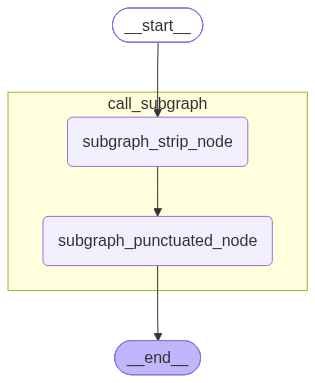

In [3]:
from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

In [6]:
histories = list(parent_graph.get_state_history(config=config))

from rich.pretty import pprint

histories.reverse()
pprint(histories, indent_guides=True)
histories.reverse()

[
│   StateSnapshot(
│   │   values={},
│   │   next=('__start__',),
│   │   config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': '',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b575-604a-bfff-44a12895e79d'
│   │   │   }
│   │   },
│   │   metadata={'source': 'input', 'step': -1, 'parents': {}},
│   │   created_at='2026-10-29T14:55:34.465949+00:00',
│   │   parent_config=None,
│   │   tasks=(
│   │   │   PregelTask(
│   │   │   │   id='1c771a05-a0b1-459e-9a9f-9d09fe0a11c2',
│   │   │   │   name='__start__',
│   │   │   │   path=('__pregel_pull', '__start__'),
│   │   │   │   error=None,
│   │   │   │   interrupts=(),
│   │   │   │   state=None,
│   │   │   │   result={'input_text': '    langgraph真好玩   '}
│   │   │   ),
│   │   ),
│   │   interrupts=()
│   ),
│   StateSnapshot(
│   │   values={'input_text': '    langgraph真好玩   '},
│   │   next=('call_subgraph',),
│   │   config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': '',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b576-6738-8000-6266c889116b'
│   │   │   }
│   │   },
│   │   metadata={'source': 'loop', 'step': 0, 'parents': {}},
│   │   created_at='2026-10-29T14:55:34.466535+00:00',
│   │   parent_config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': '',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b575-604a-bfff-44a12895e79d'
│   │   │   }
│   │   },
│   │   tasks=(
│   │   │   PregelTask(
│   │   │   │   id='eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   │   name='call_subgraph',
│   │   │   │   path=('__pregel_pull', 'call_subgraph'),
│   │   │   │   error=None,
│   │   │   │   interrupts=(),
│   │   │   │   state={
│   │   │   │   │   'configurable': {
│   │   │   │   │   │   'thread_id': '123',
│   │   │   │   │   │   'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e'
│   │   │   │   │   }
│   │   │   │   },
│   │   │   │   result={'cleaned_text': 'langgraph真好玩。'}
│   │   │   ),
│   │   ),
│   │   interrupts=()
│   ),
│   StateSnapshot(
│   │   values={'input_text': '    langgraph真好玩   ', 'cleaned_text': 'langgraph真好玩。'},
│   │   next=(),
│   │   config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': '',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b57a-6e00-8001-36f47164b76f'
│   │   │   }
│   │   },
│   │   metadata={'source': 'loop', 'step': 1, 'parents': {}},
│   │   created_at='2026-10-29T14:55:34.468349+00:00',
│   │   parent_config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': '',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b576-6738-8000-6266c889116b'
│   │   │   }
│   │   },
│   │   tasks=(),
│   │   interrupts=()
│   )
]

In [7]:
parent_config = histories[-2].config
pprint(parent_config, indent_guides=True)

{
│   'configurable': {
│   │   'thread_id': '123',
│   │   'checkpoint_ns': '',
│   │   'checkpoint_id': '1f1d3a8c-b576-6738-8000-6266c889116b'
│   }
}

In [8]:
# 查看嵌入的子图检查点信息 => 只需要查看父检查点调用子图的位置 => 添加参数 subgraphs=True
pprint(parent_graph.get_state(config=parent_config, subgraphs=True), indent_guides=True)

StateSnapshot(
│   values={'input_text': '    langgraph真好玩   '},
│   next=('call_subgraph',),
│   config={
│   │   'configurable': {
│   │   │   'thread_id': '123',
│   │   │   'checkpoint_ns': '',
│   │   │   'checkpoint_id': '1f1d3a8c-b576-6738-8000-6266c889116b'
│   │   }
│   },
│   metadata={'source': 'loop', 'step': 0, 'parents': {}},
│   created_at='2026-10-29T14:55:34.466535+00:00',
│   parent_config={
│   │   'configurable': {
│   │   │   'thread_id': '123',
│   │   │   'checkpoint_ns': '',
│   │   │   'checkpoint_id': '1f1d3a8c-b575-604a-bfff-44a12895e79d'
│   │   }
│   },
│   tasks=(
│   │   PregelTask(
│   │   │   id='eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   name='call_subgraph',
│   │   │   path=('__pregel_pull', 'call_subgraph'),
│   │   │   error=None,
│   │   │   interrupts=(),
│   │   │   state=StateSnapshot(
│   │   │   │   values={
│   │   │   │   │   'raw_text': '    langgraph真好玩   ',
│   │   │   │   │   'stripped_text': 'langgraph真好玩',
│   │   │   │   │   'punctuated_text': 'langgraph真好玩。'
│   │   │   │   },
│   │   │   │   next=(),
│   │   │   │   config={
│   │   │   │   │   'configurable': {
│   │   │   │   │   │   'thread_id': '123',
│   │   │   │   │   │   'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   │   │   │   'checkpoint_id': '1f1d3a8c-b579-6c80-8002-d0772c9cb051',
│   │   │   │   │   │   'checkpoint_map': {
│   │   │   │   │   │   │   '': '1f1d3a8c-b576-6738-8000-6266c889116b',
│   │   │   │   │   │   │   'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e': '1f1d3a8c-b579-6c80-8002-d0772c9cb051'
│   │   │   │   │   │   }
│   │   │   │   │   }
│   │   │   │   },
│   │   │   │   metadata={'source': 'loop', 'step': 2, 'parents': {'': '1f1d3a8c-b576-6738-8000-6266c889116b'}},
│   │   │   │   created_at='2026-10-29T14:55:34.467900+00:00',
│   │   │   │   parent_config={
│   │   │   │   │   'configurable': {
│   │   │   │   │   │   'thread_id': '123',
│   │   │   │   │   │   'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   │   │   │   'checkpoint_id': '1f1d3a8c-b579-608c-8001-2a4e0154dd17',
│   │   │   │   │   │   'checkpoint_map': {
│   │   │   │   │   │   │   '': '1f1d3a8c-b576-6738-8000-6266c889116b',
│   │   │   │   │   │   │   'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e': '1f1d3a8c-b579-608c-8001-2a4e0154dd17'
│   │   │   │   │   │   }
│   │   │   │   │   }
│   │   │   │   },
│   │   │   │   tasks=(),
│   │   │   │   interrupts=()
│   │   │   ),
│   │   │   result={'cleaned_text': 'langgraph真好玩。'}
│   │   ),
│   ),
│   interrupts=()
)

In [9]:
subgraph_config = histories[-2].tasks[0].state
pprint(subgraph_config, indent_guides=True)

{'configurable': {'thread_id': '123', 'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e'}}

In [10]:
# 在检查点记录时 => 使用checkpoint_ns来区别不同的子图
pprint(list(parent_graph.get_state_history(config=subgraph_config)), indent_guides=True)

[
│   StateSnapshot(
│   │   values={
│   │   │   'raw_text': '    langgraph真好玩   ',
│   │   │   'stripped_text': 'langgraph真好玩',
│   │   │   'punctuated_text': 'langgraph真好玩。'
│   │   },
│   │   next=(),
│   │   config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b579-6c80-8002-d0772c9cb051',
│   │   │   │   'checkpoint_map': {
│   │   │   │   │   '': '1f1d3a8c-b576-6738-8000-6266c889116b',
│   │   │   │   │   'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e': '1f1d3a8c-b579-6c80-8002-d0772c9cb051'
│   │   │   │   }
│   │   │   }
│   │   },
│   │   metadata={'source': 'loop', 'step': 2, 'parents': {'': '1f1d3a8c-b576-6738-8000-6266c889116b'}},
│   │   created_at='2026-10-29T14:55:34.467900+00:00',
│   │   parent_config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b579-608c-8001-2a4e0154dd17',
│   │   │   │   'checkpoint_map': {
│   │   │   │   │   '': '1f1d3a8c-b576-6738-8000-6266c889116b',
│   │   │   │   │   'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e': '1f1d3a8c-b579-608c-8001-2a4e0154dd17'
│   │   │   │   }
│   │   │   }
│   │   },
│   │   tasks=(),
│   │   interrupts=()
│   ),
│   StateSnapshot(
│   │   values={'raw_text': '    langgraph真好玩   ', 'stripped_text': 'langgraph真好玩'},
│   │   next=('subgraph_punctuated_node',),
│   │   config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b579-608c-8001-2a4e0154dd17',
│   │   │   │   'checkpoint_map': {
│   │   │   │   │   '': '1f1d3a8c-b576-6738-8000-6266c889116b',
│   │   │   │   │   'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e': '1f1d3a8c-b579-608c-8001-2a4e0154dd17'
│   │   │   │   }
│   │   │   }
│   │   },
│   │   metadata={'source': 'loop', 'step': 1, 'parents': {'': '1f1d3a8c-b576-6738-8000-6266c889116b'}},
│   │   created_at='2026-10-29T14:55:34.467595+00:00',
│   │   parent_config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b577-6de0-8000-8dd0d933c06e',
│   │   │   │   'checkpoint_map': {
│   │   │   │   │   '': '1f1d3a8c-b576-6738-8000-6266c889116b',
│   │   │   │   │   'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e': '1f1d3a8c-b577-6de0-8000-8dd0d933c06e'
│   │   │   │   }
│   │   │   }
│   │   },
│   │   tasks=(
│   │   │   PregelTask(
│   │   │   │   id='f874806d-6a8c-dca8-16fa-404d07d959fc',
│   │   │   │   name='subgraph_punctuated_node',
│   │   │   │   path=('__pregel_pull', 'subgraph_punctuated_node'),
│   │   │   │   error=None,
│   │   │   │   interrupts=(),
│   │   │   │   state=None,
│   │   │   │   result={'punctuated_text': 'langgraph真好玩。'}
│   │   │   ),
│   │   ),
│   │   interrupts=()
│   ),
│   StateSnapshot(
│   │   values={'raw_text': '    langgraph真好玩   '},
│   │   next=('subgraph_strip_node',),
│   │   config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': '123',
│   │   │   │   'checkpoint_ns': 'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e',
│   │   │   │   'checkpoint_id': '1f1d3a8c-b577-6de0-8000-8dd0d933c06e',
│   │   │   │   'checkpoint_map': {
│   │   │   │   │   '': '1f1d3a8c-b576-6738-8000-6266c889116b',
│   │   │   │   │   'call_subgraph:eefe793c-bfb7-ddff-0be8-ae68d313e47e': '1f1d3a8c-b577-6de0-8000-8dd0d933c06e'
│   │   │   │   }
│   │   │   }
│   │   },
│   │   metadata={'source': 'loop', 'step': 0, 'parents': {'': '1f1d3a8c-b576-6738-8000-6266c889116b'}},
│   │   created_at='2026-10-29T14:55:34.467118+00:00',
│   │   parent_config={
│   │   │   'configurable': {
│   │   │   │   'thread_id': 